# Used Car Price Prediction — Part 1: Exploratory Data Analysis
Dataset: Vehicle Dataset from CarDekho (Kaggle, `nehalbirla/vehicle-dataset-from-cardekho`), file `car data.csv`.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold'})
REFERENCE_YEAR = 2026
df = pd.read_csv('../data/car_data.csv')

## 1. Load and inspect

In [2]:
print('Shape:', df.shape)
df.head()

Shape: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    object 
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Kms_Driven     301 non-null    int64  
 5   Fuel_Type      301 non-null    object 
 6   Seller_Type    301 non-null    object 
 7   Transmission   301 non-null    object 
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 21.3+ KB


In [4]:
print('Missing values per column:')
print(df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())
df[df.duplicated(keep=False)]

Missing values per column:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

Duplicate rows: 2


,Car_Name,Year,Selling_Price,Present_Price,Kms_Driven,Fuel_Type,Seller_Type,Transmission,Owner
15,ertiga,2016,7.75,10.79,43000,Diesel,Dealer,Manual,0
17,ertiga,2016,7.75,10.79,43000,Diesel,Dealer,Manual,0
51,fortuner,2015,23.00,30.61,40000,Diesel,Dealer,Automatic,0
93,fortuner,2015,23.00,30.61,40000,Diesel,Dealer,Automatic,0


In [5]:
for c in ['Fuel_Type','Seller_Type','Transmission','Owner']:
    print(df[c].value_counts(), '\n')
print('Unique car names:', df['Car_Name'].nunique())

Fuel_Type
Petrol    239
Diesel     60
CNG         2
Name: count, dtype: int64 

Seller_Type
Dealer        195
Individual    106
Name: count, dtype: int64 

Transmission
Manual       261
Automatic     40
Name: count, dtype: int64 

Owner
0    290
1     10
3      1
Name: count, dtype: int64 

Unique car names: 98


No missing values. There are 2 exact duplicate rows. Categorical levels are highly imbalanced: CNG has only 2 cars, and almost all cars have `Owner = 0`. `Car_Name` has ~98 unique values for 301 rows, so it is too high-cardinality to be useful.

## 2. Target variable analysis — `Selling_Price`

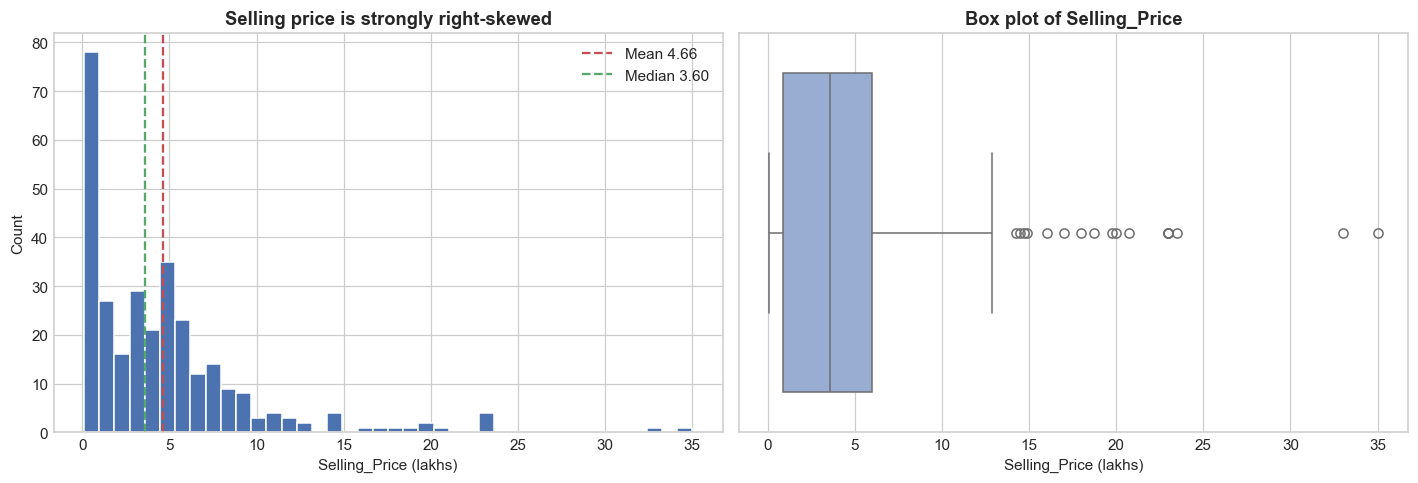

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].hist(df['Selling_Price'], bins=40, color='#4C72B0', edgecolor='white')
ax[0].axvline(df['Selling_Price'].mean(), color='#C44E52', ls='--', label=f"Mean {df['Selling_Price'].mean():.2f}")
ax[0].axvline(df['Selling_Price'].median(), color='#55A868', ls='--', label=f"Median {df['Selling_Price'].median():.2f}")
ax[0].set(title='Selling price is strongly right-skewed', xlabel='Selling_Price (lakhs)', ylabel='Count'); ax[0].legend()
sns.boxplot(x=df['Selling_Price'], ax=ax[1], color='#8FAADC')
ax[1].set(title='Box plot of Selling_Price', xlabel='Selling_Price (lakhs)')
plt.tight_layout(); plt.show()

In [7]:
s = df['Selling_Price']
summary = pd.Series({'mean': s.mean(), 'median': s.median(), 'min': s.min(), 'max': s.max(),
                     'std': s.std(), 'skewness': s.skew()}).round(3)
summary

mean         4.661
median       3.600
min          0.100
max         35.000
std          5.083
skewness     2.493
dtype: float64

The distribution is **right-skewed** (skewness ≈ 2.5): the mean (≈4.66 lakhs) is well above the median (3.6 lakhs), and a long tail of expensive cars reaches 35 lakhs. Most cars sell below ~6 lakhs.

## 3. Correlation analysis

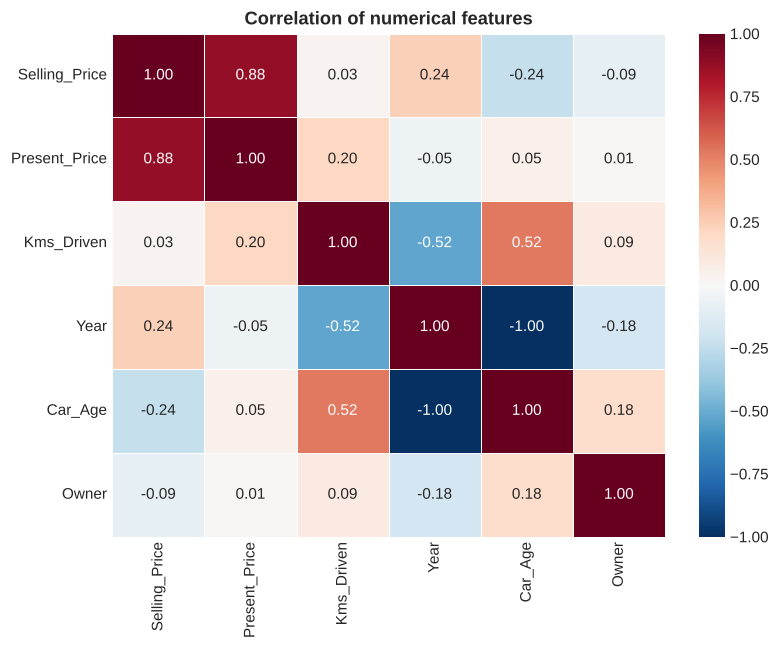

Present_Price    0.878983
Year             0.236141
Car_Age         -0.236141
Owner           -0.088344
Kms_Driven       0.029187
Name: Selling_Price, dtype: float64

In [8]:
df['Car_Age'] = REFERENCE_YEAR - df['Year']
num = df[['Selling_Price','Present_Price','Kms_Driven','Year','Car_Age','Owner']]
plt.figure(figsize=(7.5, 6))
sns.heatmap(num.corr(), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, linewidths=.5)
plt.title('Correlation of numerical features'); plt.tight_layout(); plt.show()
num.corr()['Selling_Price'].drop('Selling_Price').sort_values(key=abs, ascending=False)

`Present_Price` dominates (r ≈ 0.88). `Year`/`Car_Age` are moderate (±0.24) and are perfectly redundant with each other (r = −1), so only one should be kept. `Kms_Driven` (≈0.03) and `Owner` (≈−0.09) have almost no linear relationship with price.

## 4. Relationship plots

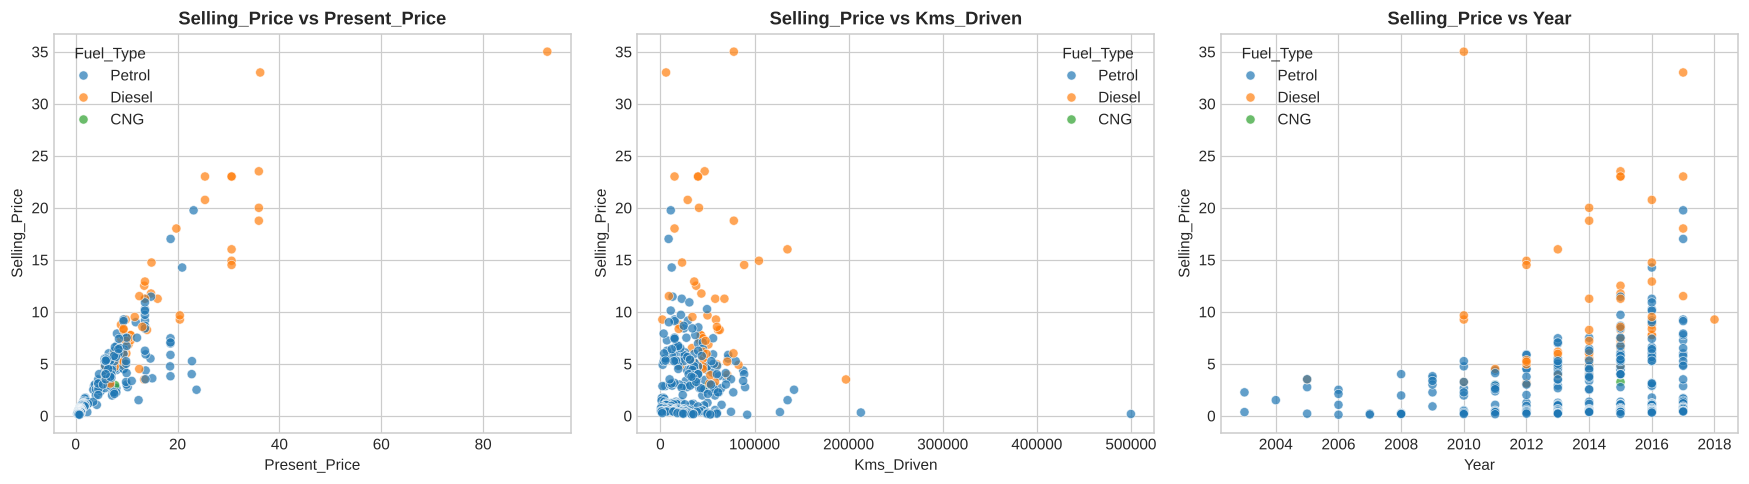

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, col in zip(ax, ['Present_Price', 'Kms_Driven', 'Year']):
    sns.scatterplot(data=df, x=col, y='Selling_Price', hue='Fuel_Type', alpha=.7, ax=a)
    a.set_title(f'Selling_Price vs {col}')
plt.tight_layout(); plt.show()

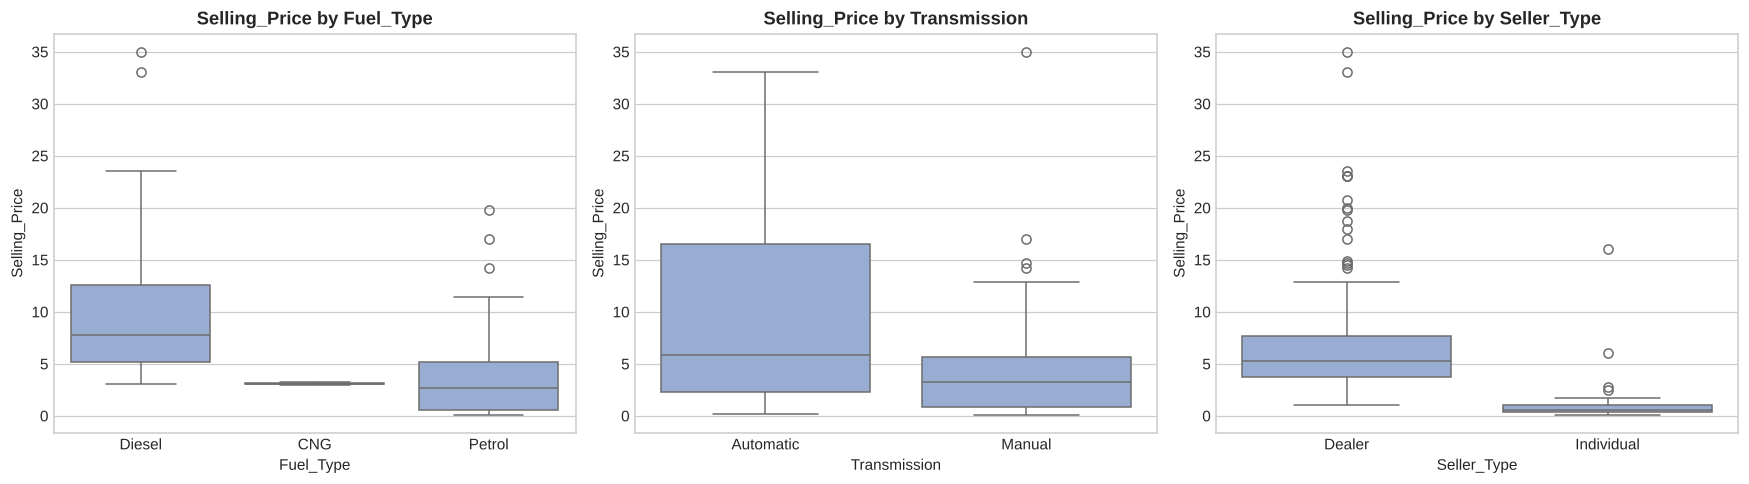

           count  median   mean
Fuel_Type                      
CNG            2    3.10   3.10
Diesel        60    7.75  10.28
Petrol       239    2.65   3.26 

              count  median  mean
Transmission                     
Automatic        40    5.80  9.42
Manual          261    3.25  3.93 

             count  median  mean
Seller_Type                     
Dealer         195    5.25  6.72
Individual     106    0.52  0.87 



In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, col in zip(ax, ['Fuel_Type', 'Transmission', 'Seller_Type']):
    order = df.groupby(col)['Selling_Price'].median().sort_values(ascending=False).index
    sns.boxplot(data=df, x=col, y='Selling_Price', order=order, ax=a, color='#8FAADC')
    a.set_title(f'Selling_Price by {col}')
plt.tight_layout(); plt.show()
for col in ['Fuel_Type', 'Transmission', 'Seller_Type']:
    print(df.groupby(col)['Selling_Price'].agg(['count','median','mean']).round(2), '\n')

Selling price rises almost linearly with `Present_Price`. Newer cars sell for more. `Kms_Driven` shows no clear trend and has one extreme value (500,000 km). Diesel, automatic and dealer-sold cars have much higher median prices; individual sellers mostly sell cheap two-wheeler/low-end listings.

## 5. Car age analysis (reference year 2026)

count    301.000000
mean      12.372093
std        2.891554
min        8.000000
25%       10.000000
50%       12.000000
75%       14.000000
max       23.000000
Name: Car_Age, dtype: float64


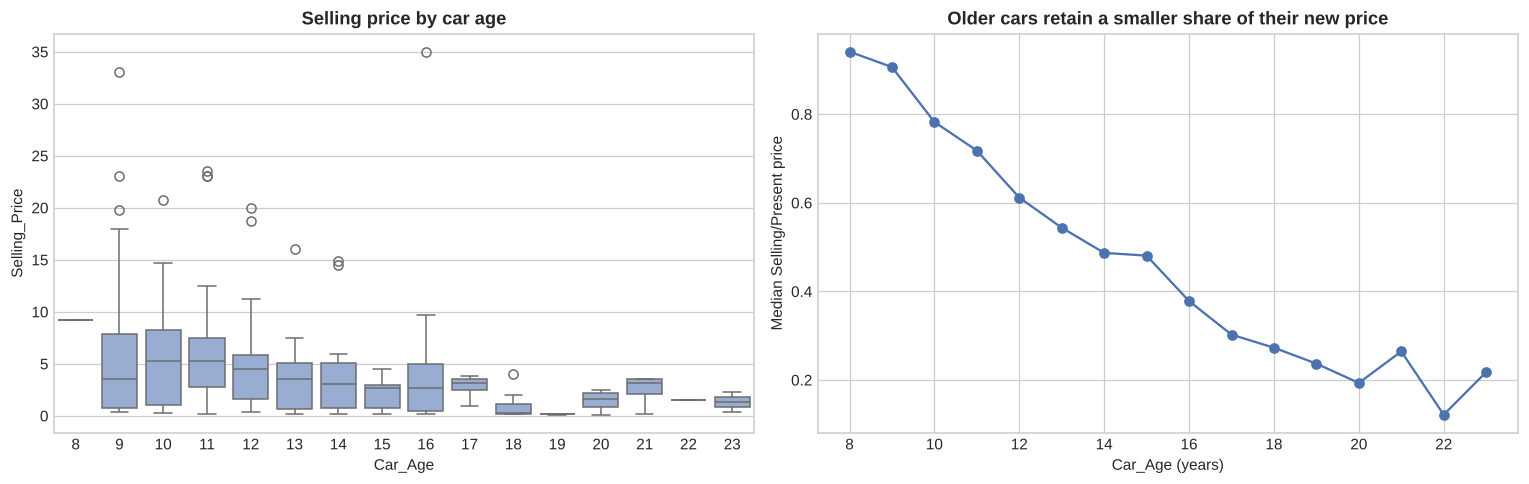

In [11]:
print(df['Car_Age'].describe())
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=df, x='Car_Age', y='Selling_Price', ax=ax[0], color='#8FAADC')
ax[0].set_title('Selling price by car age')
ratio = (df['Selling_Price'] / df['Present_Price']).groupby(df['Car_Age']).median()
ax[1].plot(ratio.index, ratio.values, marker='o', color='#4C72B0')
ax[1].set(title='Older cars retain a smaller share of their new price', xlabel='Car_Age (years)', ylabel='Median Selling/Present price')
plt.tight_layout(); plt.show()

Car ages range from 8 to 23 years (relative to 2026). Prices fall with age, and the clearest view is the retained-value ratio: 9-year-old cars keep about 90% of their showroom price, 13-year-old cars about half, and cars 17+ years old under a third. The same `Car_Age = 2026 − Year` definition is used in training and in the Streamlit app.

## 5b. Unusual values

In [12]:
print(df.sort_values('Kms_Driven', ascending=False)[['Car_Name','Year','Kms_Driven','Selling_Price','Present_Price']].head(5))
print()
print(df.sort_values('Selling_Price', ascending=False)[['Car_Name','Year','Kms_Driven','Selling_Price','Present_Price']].head(5))

          Car_Name  Year  Kms_Driven  Selling_Price  Present_Price
196      Activa 3g  2008      500000           0.17           0.52
179  Honda Karizma  2010      213000           0.31           1.05
84          innova  2005      197176           3.49          13.46
85           camry  2006      142000           2.50          23.73
77         corolla  2004      135154           1.50          12.35

        Car_Name  Year  Kms_Driven  Selling_Price  Present_Price
86  land cruiser  2010       78000           35.0          92.60
64      fortuner  2017        6000           33.0          36.23
63      fortuner  2015       47000           23.5          35.96
51      fortuner  2015       40000           23.0          30.61
93      fortuner  2015       40000           23.0          30.61


One car reports 500,000 km — more than double the next-highest value (~213,000) and implausible for its listing. The highest selling prices (land cruiser, fortuner) are genuine luxury cars consistent with their `Present_Price`, so they are kept.

## 6. Key findings
1. **`Present_Price` is by far the strongest predictor** (r ≈ 0.88 with `Selling_Price`); the relationship is close to linear.
2. **Age matters**: newer cars sell for more and retain a larger fraction of their showroom price. `Year` and `Car_Age` are perfectly redundant, so only `Car_Age` is kept.
3. **Categoricals carry real signal**: Diesel, Automatic and Dealer listings have clearly higher prices. They are nominal, so they will be one-hot encoded.
4. **Low-signal features**: `Kms_Driven` and `Owner` are weakly related to price (Owner is ~96% zeros; CNG has only 2 rows). `Car_Name` is high-cardinality and is dropped.
5. **Target is right-skewed** with a few expensive cars, so RMSE will be driven by high-price cars; tree models handle the non-linearity and interactions (age × price) well.

**Preprocessing plan:** drop the 2 duplicate rows; create `Car_Age`; drop `Year` and `Car_Name`; one-hot encode `Fuel_Type`, `Seller_Type`, `Transmission`; scale numerics for linear models only; remove training rows with `Kms_Driven > 300,000` (rule fixed here, before any modelling). All learned preprocessing lives inside a scikit-learn `Pipeline`.